# Mínimos cuadrados

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#### Problema 1
Una pelota es arrojada hacia arriba. Una cámara de fotos toma fotos cada 0.1 segundos y a partir de esas fotos se calcula la altura de la pelota en cada instante.
En el archivo `altura_pelota.csv` se encuentran las mediciones obtenidas.

Sabiendo que la altura de la pelota depende del tiempo en forma cuadrática 
$h(t) = c_0 + c_1 t + c_2 t^2,$ estimar los valores de $c_0, c_1, c_2$ ajustando los datos por mínimos cuadrados.

Resolvemos el problema mediante las ecuaciones normales
$
A^tA c = A^ty
$
para una matriz $A$ apropiada.


**Ejercicios**

1. Obtener la matriz A.
2. Resolver por mínimos cuadrados utilizando la función de escalonamiento utilizada en el laboratorio de ALC (no utilizar el solve de numpy o scipy, etc.)
3. Graficar la nube de puntos y la función encontrada.
4. Es posible saber en que punto la pelota toca el suelo para los valores encontrados?

In [2]:
import pandas as pd   
# Los datos están en español! 
datos = pd.read_csv("altura_pelota.csv", sep=";", decimal=",")   # dataFrame
datos.head(3)

FileNotFoundError: [Errno 2] No such file or directory: 'altura_pelota.csv'

In [ ]:
# Convertimos los datos a np.array
datosNP = datos.to_numpy()
print(datosNP.shape)

(101, 2)


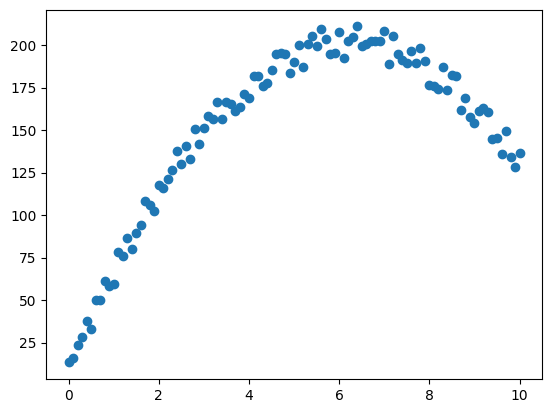

In [ ]:
# Graficamos
plt.scatter(datosNP[:,0], datosNP[:,1])

Resolver a partir de aqui.

In [ ]:
from row_echenlon import row_echelon
from scipy.linalg import solve_triangular

In [ ]:
num_variables = 3
#Armo la matriz A
A = np.zeros((len(datosNP),num_variables))
A[:,0] = 1
A[:,1] = datosNP[:,0]
A[:,2] = datosNP[:,0]**2

# Construyo la matriz normal de A
M = np.zeros((num_variables,num_variables+1))
M[:,:3] = A.T @ A
M[:,-1] = A.T @ datosNP[:,1]

#Resuelvo el sistema
escalonado_A = row_echelon(M)
c0,c1,c2 = solve_triangular(escalonado_A[:3,:3],escalonado_A[:3,-1])

In [ ]:
def funcion(t):
    return c0 + c1*t +c2*t**2

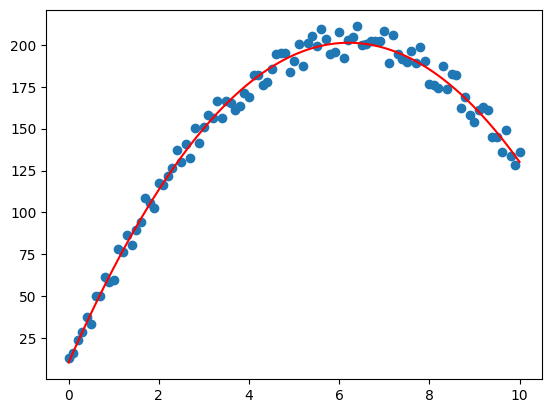

In [ ]:
# Graficamos
plt.scatter(datosNP[:,0], datosNP[:,1])
datos_aprox = [funcion(x) for x in datosNP[:,0].T]
plt.plot(datosNP[:,0], datos_aprox,c='r')

# Mínimos cuadrados para sumas de funciones

Para datos $(t_j, y_j)$, $1 \le j \le m$ queremos ajustar una función del tipo 
$$
y = c_1 f_1(t) + \dots + c_s f_s(t)
$$

Ejemplo: $y = a + b t + c t^2$.

RECORDAR: reemplazando los valores de $t$ e $y$ por los datos en la tabla obtenemos un sistema **lineal** de ecuaciones, donde las incógnitas son los $c_i$:

$$
\begin{align}
y_1 &= c_1 f_1(t_1) + \dots + c_s f_s(t_1) \\
&\vdots\\
y_m &= c_1 f_1(t_m) + \dots + c_s f_s(t_m)
\end{align}
$$

Cuando tenemos más datos (ecuaciones) que incógnitas, usamos mínimos cuadrados para obtener una solución aproximada.



#### Problema
Ajustar por mínimos cuadrados una función del tipo
$$
y = c_1 t^2 + c_2 e^t + c_3 t
$$
a los datos

|t|1|2|4|6|8|
| --- | --- | --- | --- | --- | --- |
|y|6|10|10|8|10|

In [ ]:
# Vectores de datos
ti = np.array([1, 2, 4, 6, 8])
yi = np.array([6, 10, 10, 8, 10])

# a) Definimos las funciones
def f1(t):
    return(t**2)

def f2(t):
    return(np.e**t)

def f3(t):
    return(t)

**Ejercicios**
1. Construir la matriz A a partir de la ecuación de y
2. Econtrar por mínimos cuadrados los coeficientes $$c_1, c_2, c_3$$
3. Verificar gráficamente imprimiendo los puntos (t,y) y la función contínua obtenida por los mínimos cuadrados.


In [ ]:
num_variables = 3
#Armo la matriz A
A = np.zeros((len(ti),num_variables))
A[:,0] = f1(ti)
A[:,1] = f2(ti)
A[:,2] = f3(ti)

# Construyo la matriz normal de A
M = np.zeros((num_variables,num_variables+1))
M[:,:3] = A.T @ A
M[:,-1] = A.T @ yi

#Resuelvo el sistema
escalonado_A = row_echelon(M)
c0,c1,c2 = solve_triangular(escalonado_A[:3,:3],escalonado_A[:3,-1])

In [ ]:
def funcion(t):
    return c0*f1(t) + c1*f2(t) +c2*f3(t)

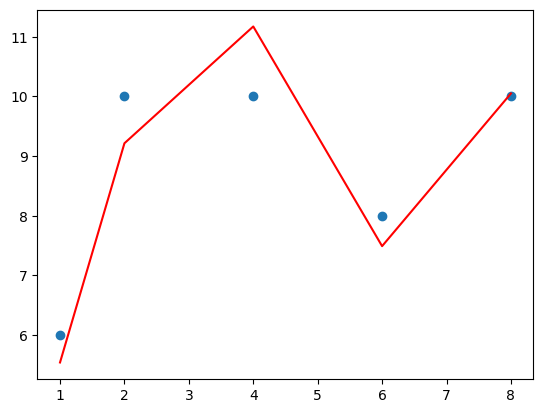

In [ ]:
# Graficamos
plt.scatter(ti, yi)
datos_aprox = [funcion(x) for x in ti]
plt.plot(ti, datos_aprox,c='r')